In [1]:
%env CUDA_DEVICE_ORDER=PCI_BUS_ID
%env CUDA_VISIBLE_DEVICES=0
%pylab inline
%load_ext autoreload
%autoreload 2

env: CUDA_DEVICE_ORDER=PCI_BUS_ID
env: CUDA_VISIBLE_DEVICES=0


ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/traitlets/traitlets.py", line 651, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/zmq/eventloop/zmqstream.py", line 566, in _log_error
    f.result()
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/ipykernel/kernelbase.py", line 301, in dispatch_control
    async with self._control_lock:
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/traitlets/traitlets.py", line 706, in __get__
    return self.get(obj, cls)  # type:ignore[return-value]
  File "/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/pyt

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
import json
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
import os
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.manifold import TSNE
from openTSNE import TSNE
import colorcet as cc

/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from ssl_neuron.datasets import GraphDataset
from ssl_neuron.utils import plot_neuron, plot_tsne, neighbors_to_adjacency_torch, compute_eig_lapl_torch_batch
from ssl_neuron.graphdino import create_model

In [4]:
TRIAL = "trial3"

#### Load config

In [5]:
config = json.load(open(f'../configs/{TRIAL}.json'))

#### Load model + checkpoint

In [6]:
cell_meta = pd.read_csv(os.path.join(config['data']['path'], 'cell_meta.csv'))
cell_meta['cell_id'] = cell_meta['cell_id'].astype(str)

In [7]:
cell_meta

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,valid_status,celltype_final,valid_celltype_final,celltype_final_decision,soma_x_um,soma_y_um,soma_z_um
0,720575940537162675,623.088321,271.935098,-21.628196,9054,8096,958,0,RGC,True,True,NaN,False,NaN,623.088,271.935,-21.6282
1,720575940537274291,483.576538,891.599123,-14.109626,5112,3943,1169,0,RGC,True,True,ON alpha,True,both_strong,483.577,891.599,-14.1096
2,720575940537284275,477.293864,607.582202,-18.812998,6950,6137,813,0,RGC,True,True,Sustained suppressed-by-contrast strong surrou...,True,both_weak,477.294,607.582,-18.8130
3,720575940537313971,778.958349,719.019178,-14.450323,8642,7627,1015,0,RGC,True,True,ON delayed,True,both_strong,778.958,719.019,-14.4503
4,720575940537343155,283.318443,409.646856,-16.305329,9935,8934,1001,0,RGC,True,True,OFF vertical OS - asymmetric,True,both_strong,283.318,409.647,-16.3053
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3685,720575940589082516,271.145212,1050.133062,-13.881681,9780,9657,123,0,RGC,True,True,NaN,False,NaN,271.145,1050.130,-13.8817
3686,720575940589088148,281.992055,1067.835937,-14.430131,17577,14828,2749,0,RGC,True,True,NaN,False,NaN,281.992,1067.840,-14.4301
3687,720575940589111700,851.058152,1070.755962,-14.051774,13661,11003,2658,0,RGC,True,True,HD2,True,both_strong,851.058,1070.760,-14.0518
3688,720575940589184404,1036.643098,993.958841,-13.925180,16997,15377,1620,0,RGC,True,True,HD1,True,both_weak,1036.640,993.959,-13.9252


In [8]:
model = create_model(config)

In [9]:
state_dict = torch.load(f'../ckpts/{TRIAL}.pt')

In [10]:
model.load_state_dict(state_dict)

<All keys matched successfully>

In [11]:
model.eval()
model.cuda();

#### Load dataset

In [12]:
dset = GraphDataset(config, mode='all')

100%|██████████| 3690/3690 [05:03<00:00, 12.14it/s]


In [13]:
feat, neigh, cell_id = dset.__getsingleitem__(0)

In [14]:
feat.shape, len(neigh)

((1000, 3), 1000)

#### Plot neuron

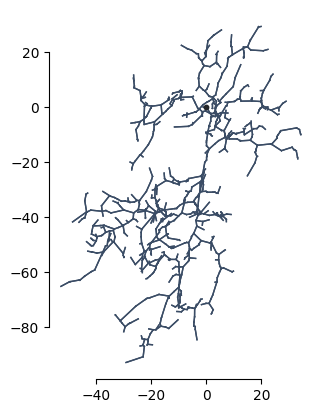

In [15]:
plot_neuron(neigh, feat)

#### Run inference

In [16]:
cell_meta.index[cell_meta['cell_id'] == cell_id]

Int64Index([0], dtype='int64')

In [17]:
latents = np.zeros((dset.num_samples, config['model']['dim']))

cell_meta['latent'] = pd.Series(
    [None] * len(cell_meta),
    index=cell_meta.index,
    dtype=object
)

cell_meta['cell_id'] = cell_meta['cell_id'].astype(str)

for i in tqdm(range(dset.num_samples)):
    feat, neigh, cell_id = dset.__getsingleitem__(i)
    cell_id = str(cell_id)

    adj = neighbors_to_adjacency_torch(
        neigh, list(neigh.keys())
    ).float().cuda()[None, :]

    lapl = compute_eig_lapl_torch_batch(
        adj,
        pos_enc_dim=config['model']['pos_dim']
    ).float().cuda()

    feat = torch.from_numpy(feat).float().cuda()[None, :]

    with torch.no_grad():
        embedding = model.student_encoder.forward(feat, adj, lapl)[0]
        embedding = embedding.cpu().numpy().squeeze()

    latents[i] = embedding

    mask = cell_meta['cell_id'] == cell_id

    for idx in cell_meta.index[mask]:
        cell_meta.at[idx, 'latent'] = embedding

print("\nEmbedding extraction complete!")
print("Latents matrix shape:", latents.shape)
print("Rows with embeddings:", cell_meta['latent'].notna().sum())


100%|██████████| 3690/3690 [04:11<00:00, 14.66it/s]


Embedding extraction complete!
Latents matrix shape: (3690, 32)
Rows with embeddings: 3690


<ErrorbarContainer object of 3 artists>

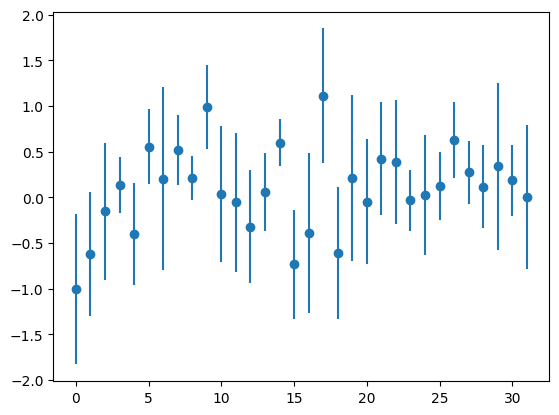

In [18]:
plt.scatter(np.arange(config['model']['dim']), latents.mean(axis=0))

plt.errorbar(np.arange(config['model']['dim']), latents.mean(axis=0), yerr = latents.std(axis=0), fmt='none')

In [28]:
cell_meta['latent']

0       [-0.6635638, -0.47945184, 0.050245672, -0.2382...
1       [0.45780945, -1.7968636, -1.2167013, 0.4888189...
2       [-1.509097, 0.5007739, 0.32065892, 0.16036831,...
3       [-1.4044142, -0.24350081, -0.29890692, 0.42757...
4       [-0.04817871, -0.78356516, 0.31976593, 0.04934...
                              ...                        
3685    [1.1664165, -1.7108176, -1.0605594, 0.95608735...
3686    [-0.7025821, -0.016358823, -0.6138213, 0.14261...
3687    [-0.1919393, -1.2633163, -0.6361423, -0.085971...
3688    [-0.3147779, -1.1316181, -0.7115738, 0.0011625...
3689    [-1.4227091, -0.39347506, 1.0669268, 0.0448193...
Name: latent, Length: 3690, dtype: object

In [25]:
def plot_tsne(cell_meta, unknown_labels=False, color_by='celltype', perplexity=30):

    if unknown_labels:
        plot_df = cell_meta.copy()
    else:
        plot_df = cell_meta[cell_meta['celltype_final'].notna()].copy()

    X = np.stack(plot_df['latent'].values).astype(np.float32)

    print("Embedding shape:", X.shape)
    print("Embedding dtype:", X.dtype)

    # Run t-SNE
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        initialization='random',
        learning_rate=200.0,
        n_jobs=-1
    )

    X_tsne = np.array(tsne.fit(X))

    plot_df['TSNE1'] = X_tsne[:, 0]
    plot_df['TSNE2'] = X_tsne[:, 1]

    fig, ax = plt.subplots(figsize=(8, 5) if color_by != 'celltype' else (12, 5))

    # 1. Color by cell type
    if color_by == 'celltype':

        celltypes = sorted(plot_df['celltype_final'].dropna().unique())
        colors = cc.glasbey[:len(celltypes)]
        color_dict = dict(zip(celltypes, colors))

        if unknown_labels:
            missing = plot_df[plot_df['celltype_final'].isna()]

            ax.scatter(
                missing['TSNE1'],
                missing['TSNE2'],
                color='lightgrey',
                label='Unknown',
                s=15,
                alpha=0.5,
                zorder=1
            )

        for celltype, group in plot_df.dropna(
            subset=['celltype_final']
        ).groupby('celltype_final'):

            ax.scatter(
                group['TSNE1'],
                group['TSNE2'],
                color=color_dict[celltype],
                label=str(celltype),
                s=15,
                alpha=0.8,
                zorder=2
            )

        ax.legend(
            title='Cell Type',
            bbox_to_anchor=(1.02, 1),
            loc='upper left',
            ncol=2,
            fontsize=8,
            markerscale=1.5
        )

    # 2. Color by a continuous variable
    elif color_by in plot_df.columns and color_by != 'none':

        values = plot_df[color_by].to_numpy(dtype=float)

        vmin, vmax = np.nanpercentile(values, [2, 98])

        vcenter = np.nanmean(values)

        norm = TwoSlopeNorm(
            vmin=vmin,
            vcenter=vcenter,
            vmax=vmax
        )

        cmap = mpl.colormaps['RdBu_r']

        sc = ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            c=values,
            cmap=cmap,
            norm=norm,
            s=15,
            alpha=0.8
        )

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label(color_by)

    # 3. Single color
    elif color_by == 'none':

        ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            color='steelblue',
            s=15,
            alpha=0.7
        )

    else:
        raise ValueError(
            f"Unknown color_by='{color_by}'. "
            "Use 'celltype', 'none', or a numerical column name."
        )

    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.set_title(f't-SNE of Neuron Embeddings (colored by {color_by})')

    plt.tight_layout()
    plt.show()

    return plot_df

Embedding shape: (2915, 32)
Embedding dtype: float32


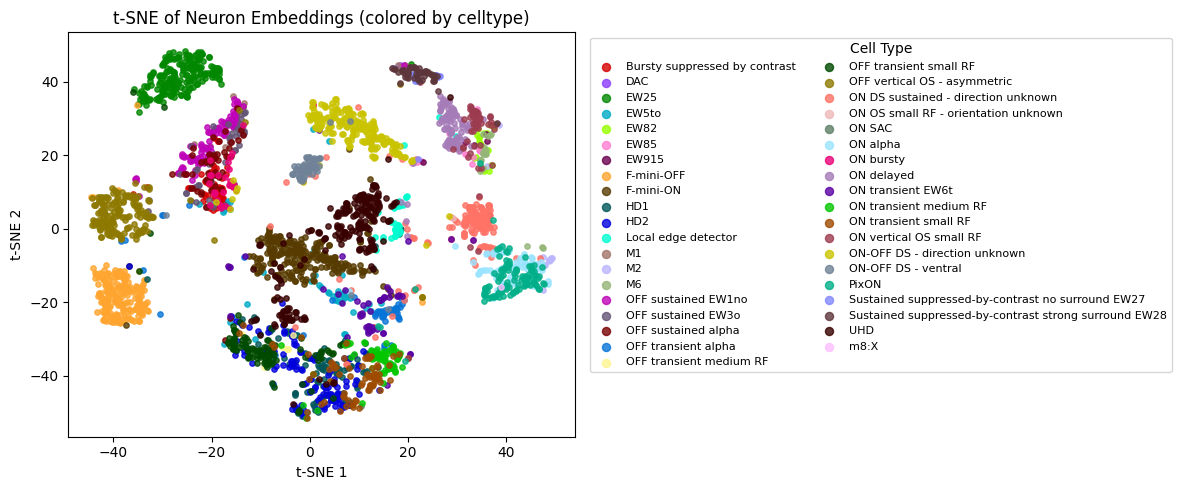

Embedding shape: (3690, 32)
Embedding dtype: float32


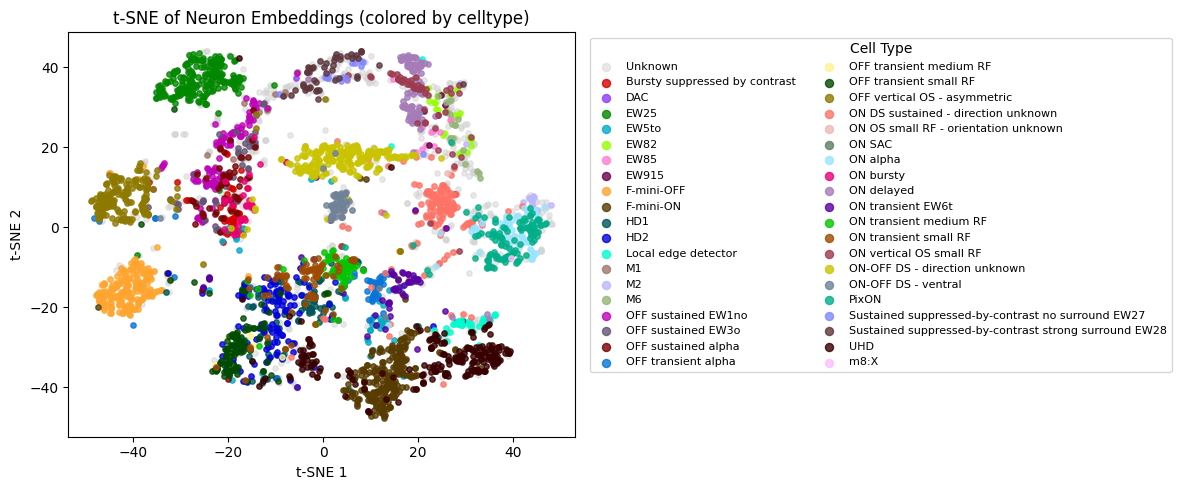

Embedding shape: (2915, 32)
Embedding dtype: float32


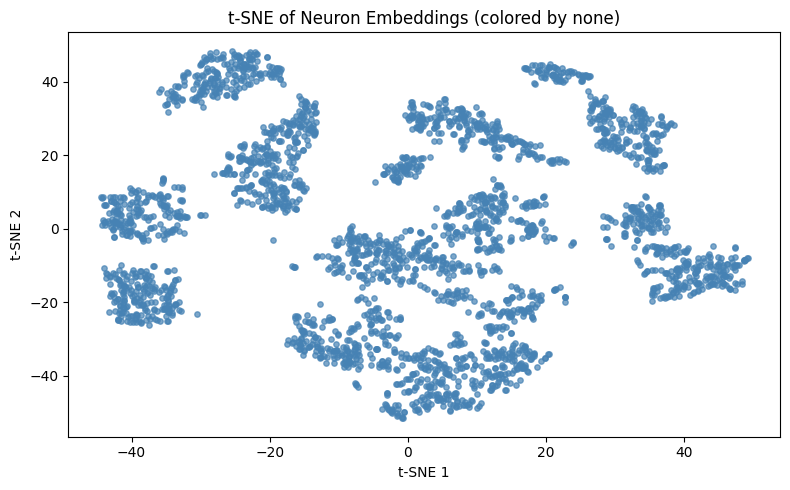

Embedding shape: (2915, 32)
Embedding dtype: float32


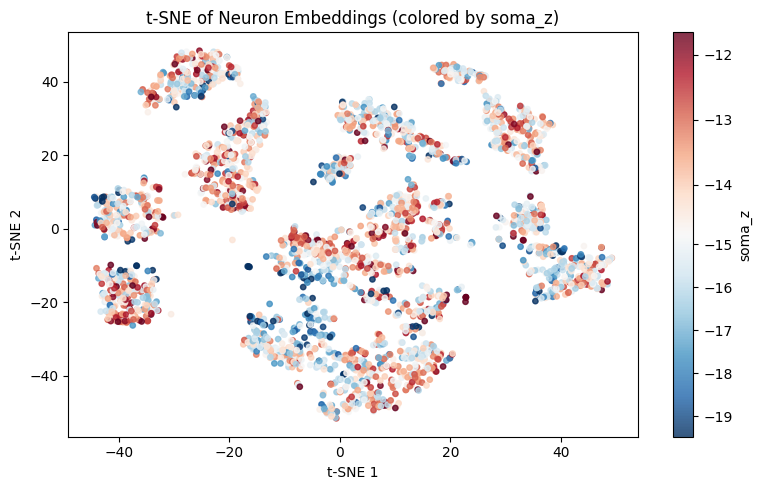

In [26]:
plot_df = plot_tsne(cell_meta, unknown_labels=False, color_by='celltype')

plot_df = plot_tsne(cell_meta, unknown_labels=True, color_by='celltype')

plot_df = plot_tsne(cell_meta, color_by='none')

plot_df = plot_tsne(cell_meta, color_by='soma_z')

Training losses:
[6.84321404 6.69458342 6.20408201 5.91739655 5.62212658 5.44164705
 5.24177933 5.02064753 4.67968798 4.3710947  4.01220226 3.76937056
 3.59485865 3.39425278 3.35385799 3.173666   3.15655327 3.02949572
 2.89456582 2.81860614 2.73698616 2.63492036 2.55199099 2.4181664
 2.24942446 2.03629446 1.89999509 1.80613875 1.71853495 1.63240862
 1.60042691 1.60116875 1.54260194 1.56850708 1.58566499 1.53134775
 1.53490746 1.52653313 1.53950453 1.51749229 1.49424958 1.47728801
 1.4387635  1.42249429 1.37479949 1.34280801 1.33625031 1.28021336
 1.27546155 1.27998865 1.24103379 1.18379319 1.19609284 1.19396007
 1.16018844 1.16161847 1.11552787 1.13005579 1.08130062 1.1204896
 1.07019436 1.0423367  1.05474126 1.05369318 1.04724574 1.02878749
 1.01295424 0.98338735 0.98448861 1.00918353 1.0378834  1.03381467
 1.01126552 1.04251695 1.01271892 0.95700729 0.9535408  0.91316706
 0.88491815 0.86784637 0.8624981  0.82351148 0.83559197 0.81958574
 0.81476462 0.79897332 0.79319042 0.77903473 0.

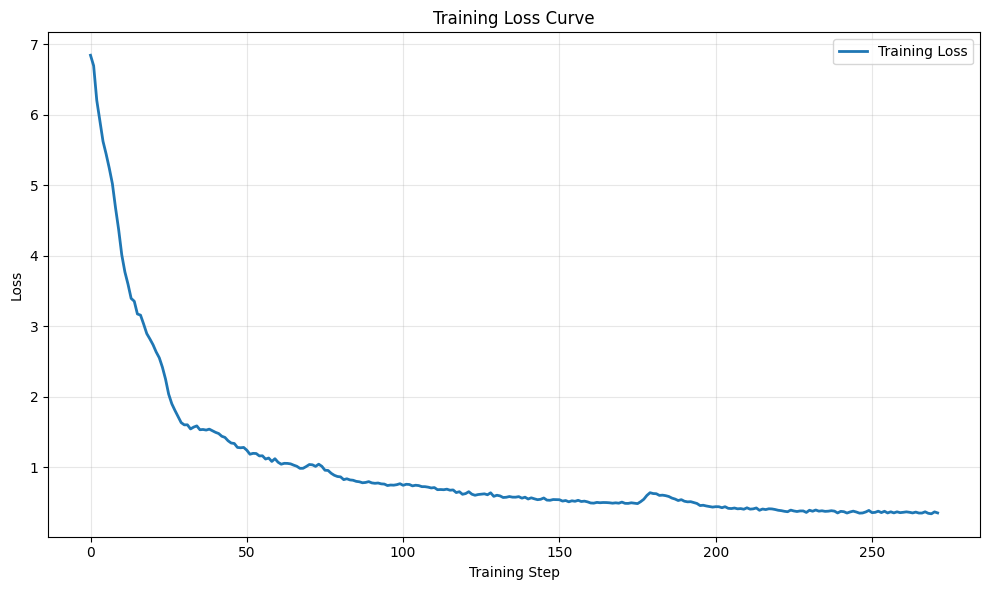

In [27]:
loss_path = Path("..") / Path(config['trainer']['losses_dir']) / Path(TRIAL) / "training_loss.npy"
losses = np.load(loss_path)

print("Training losses:")
print(losses)

print(f"Number of training steps: {len(losses)}")
print(f"Initial loss: {losses[0]:.6f}")
print(f"Final loss: {losses[-1]:.6f}")
print(f"Minimum loss: {np.min(losses):.6f}")

plt.figure(figsize=(10, 6))
plt.plot(losses, label="Training Loss", linewidth=2)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_loss_curve.png", dpi=300)
plt.show()